# Gesichtserkennung - Emotionserkennung 

Das Kameraprogramm zeigt Gesichtsregionen und Klassifikatorwerte und schreibt CSV-Logs. Hier können Sie Daten für den Programmentwurf aufnehmen.


## Vorbereitung und Abhängigkeiten
Alle folgenden Dateien müssen im selben Projektordner liegen:

- dieses Notebook
- `kamera_gesicht_v16.py` (aktuelles Kameraprogramm)
- `gesichts_klassifikatoren.py` (bestehende Klassifikatoren)
- `log_show.py` (neue Auswertung)

Die nachfolgende Zelle legt mit `PROJEKTORDNER` den gemeinsamen Ordner fest.
`Path.cwd()` ist das aktuelle Arbeitsverzeichnis des Notebook-Kernels, nicht zwingend
der Speicherort des Notebooks. Bei Bedarf hier den absoluten Ordnerpfad eintragen.

**Python-Pakete:** `numpy`, `mediapipe`, OpenCV (`cv2`, mit Fensterunterstützung),
`pandas` und `matplotlib`. `IPython` ist Teil der Notebook-Umgebung und wird für Tabellen verwendet.
`pathlib`, `subprocess`, `sys`, `csv`, `time`, `dataclasses`, `datetime`,
`urllib.request`, `types`, `importlib` und `json` gehören zur Python-Standardbibliothek.


Die Kamera benötigt unter macOS eine Kamerafreigabe (ggf. müssen Sie die Kamera noch wählen)
für die ausführende Anwendung. Das Gesichtsmodell wird beim ersten Kamerastart
in den Projektordner heruntergeladen (Internet erforderlich).

Python 3.12 aufwärts sollte laufen.

In [1]:
from pathlib import Path
import sys
import subprocess
import importlib
import importlib.util

PROJEKTORDNER = Path.cwd().resolve()  # ggf. Path("/Users/.../camera-operations")
INSTALL_MISSING = True

pakete = {
    "numpy": "numpy",
    "cv2": "opencv-python",  # GUI-Paket; keine headless-Variante installieren
    "mediapipe": "mediapipe",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "IPython": "ipython",
}
fehlend = [pip_name for modul, pip_name in pakete.items()
           if importlib.util.find_spec(modul) is None]
if fehlend:
    if not INSTALL_MISSING:
        raise ModuleNotFoundError(
            "Fehlende Pakete: " + ", ".join(fehlend)
            + ". INSTALL_MISSING = True setzen und diese Zelle erneut ausführen."
        )
    subprocess.run([sys.executable, "-m", "pip", "install", *fehlend], check=True)
    raise RuntimeError("Installation beendet. Kernel neu starten und diese Zelle erneut ausführen.")

import numpy as np
import cv2
import mediapipe as mp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

benoetigt = ["VideoCapture", "imshow", "waitKey", "Sobel", "remap", "getAffineTransform"]
nicht_vorhanden = [name for name in benoetigt if not hasattr(cv2, name)]
if nicht_vorhanden:
    raise RuntimeError("Unvollständiges cv2-Modul: " + ", ".join(nicht_vorhanden))
if not hasattr(mp, "tasks") or not hasattr(mp.tasks.vision, "FaceLandmarker"):
    raise RuntimeError("MediaPipe Tasks mit FaceLandmarker ist erforderlich.")
if hasattr(cv2, "getBuildInformation"):
    gui_zeile = next((line for line in cv2.getBuildInformation().splitlines()
                      if line.strip().startswith("GUI:")), "")
    if gui_zeile and "NONE" in gui_zeile.upper():
        raise RuntimeError("OpenCV wurde ohne GUI installiert. Für das Kamerafenster ist eine GUI-Version erforderlich.")

lokale_dateien = ["kamera_gesicht_v16.py", "gesichts_klassifikatoren.py", "log_show.py"]
fehlende_dateien = [name for name in lokale_dateien if not (PROJEKTORDNER / name).is_file()]
if fehlende_dateien:
    raise FileNotFoundError(f"In {PROJEKTORDNER} fehlen: " + ", ".join(fehlende_dateien))
if str(PROJEKTORDNER) not in sys.path:
    sys.path.insert(0, str(PROJEKTORDNER))

# Lokale Module ebenfalls prüfen; der Import aktiviert die Kamera nicht.
import gesichts_klassifikatoren
kamera_modul = importlib.import_module("kamera_gesicht_v16")
from log_show import auswerten

print("Python:", sys.executable)
print("Projektordner:", PROJEKTORDNER)
for name, modul in [("NumPy", np), ("OpenCV", cv2), ("MediaPipe", mp),
                    ("pandas", pd), ("matplotlib", importlib.import_module("matplotlib"))]:
    print(f"{name}: {getattr(modul, '__version__', 'Version nicht angegeben')}")
print("Abhängigkeiten und lokale Dateien sind verfügbar.")


Python: c:\Users\reichard\.conda\envs\emotionen\python.exe
Projektordner: C:\Users\reichard\Downloads\KI-emo-task
NumPy: 2.5.5
OpenCV: 5.0.0
MediaPipe: 1.2.3
pandas: 3.1.1
matplotlib: 3.11.2
Abhängigkeiten und lokale Dateien sind verfügbar.


## Kameraaufnahmen durchführen
Die folgende Zelle startet Version 16 mit demselben Python-Interpreter wie das Notebook.
Das Notebook wartet, bis das Kamerafenster beendet wird.

- **Leertaste / Escape:** beenden und Logdatei schließen
- **C:** Augen etwa 1,5 Sekunden geschlossen halten und kalibrieren
- **O:** Augen etwa 1,5 Sekunden **weit aufgerissen** halten und kalibrieren
- **R:** Augen-Kalibrierung zurücksetzen

Logdateien liegen im Unterordner `logs` neben dem Kameraprogramm.


Bildgröße: (480, 640, 3)
Mittlere Helligkeit: 97.2 von 255


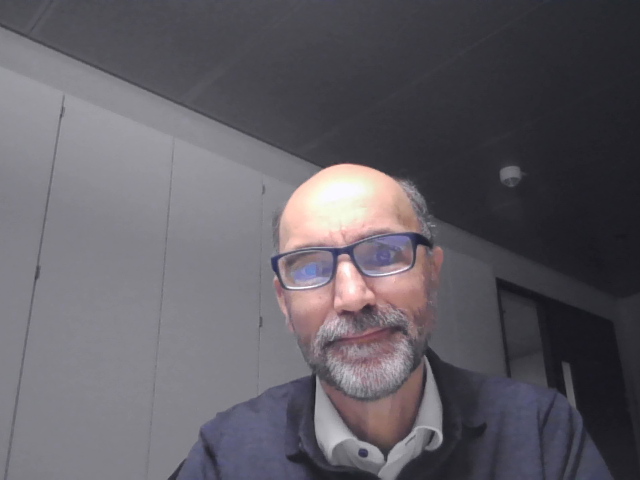

In [ ]:
## Test der Kamera

import cv2
from IPython.display import display, Image

cap = cv2.VideoCapture(1, cv2.CAP_DSHOW)

# Kamera 1 ausgewählt - bitte prüfen, ggf. Kamera 0 verwenden, falls keine Kamera 1 vorhanden ist.

bild = None

try:
    for _ in range(10):
        ok, frame = cap.read()
        if ok and frame is not None and frame.size:
            bild = frame
finally:
    cap.release()

if bild is None:
    print("Keine Bilddaten erhalten.")
else:
    print(f"Bildgröße: {bild.shape}")
    print(f"Mittlere Helligkeit: {bild.mean():.1f} von 255")
    ok, png = cv2.imencode(".png", bild)
    if ok:
        display(Image(data=png.tobytes()))

In [ ]:

PROJEKTORDNER = Path.cwd()
script = PROJEKTORDNER / "kamera_gesicht_v16.py"

ergebnis = subprocess.run(
    [
        sys.executable,
        str(script),
        "--platform", "windows",
        "--camera", "1",  # hier ggf. andere Kamera-ID angeben, z.B. "0" für die erste Kamera
    ],
    cwd=PROJEKTORDNER,
    capture_output=True,
    text=True,
)

print(ergebnis.stdout)
print(ergebnis.stderr)

Lade Gesichtsmodell einmalig herunter ...
Oeffne Kamera 1, Plattform=windows, Backend=DirectShow ...
Kamera geoeffnet.
CSV-Logging gestartet: C:\Users\reichard\Downloads\KI-emo-task\logs\klassifikatoren_20261116_094851_086428.csv
CSV-Log gespeichert: C:\Users\reichard\Downloads\KI-emo-task\logs\klassifikatoren_20261116_094851_086428.csv (328 Zeilen)

W0000 00:00:1794818931.144618   29680 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794818931.151630   43204 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794818931.163443   38240 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



## Letzte Logdatei auswerten
`log_show.py` sucht die zuletzt geänderte Logdatei. Angezeigt werden eine
Sitzungsübersicht, die deskriptive Statistik und schmale Zeitdiagramme untereinander
mit gemeinsamer Zeitachse. 



Logdatei: C:\Users\reichard\Downloads\KI-emo-task\logs\klassifikatoren_20261116_094851_086428.csv
Statistik pro Logzeile; wiederholte Kantenwerte werden mitgezählt.


,Wert
Messzeilen,328.000
Letzter Zeitwert [s],10.984
Erfasste Zeitspanne [s],10.890
Gesicht erkannt [% gültiger Zeilen],100.000
Brille erkannt [% gültiger Zeilen],0.000


,Messgröße,Anzahl gültig,Anzahl fehlend,Mittelwert,Standardabweichung,Minimum,Q25,Median,Q75,Maximum
Logspalte,,,,,,,,,,
auge_links_oeffnung,Auge links – Öffnung,328.0,0,0.733,0.093,0.407,0.689,0.754,0.788,0.855
auge_rechts_oeffnung,Auge rechts – Öffnung,328.0,0,0.780,0.107,0.353,0.744,0.813,0.846,0.935
auge_links_roh,Auge links – Öffnung ungeglättet,328.0,0,0.739,0.093,0.365,0.700,0.761,0.804,0.875
auge_rechts_roh,Auge rechts – Öffnung ungeglättet,328.0,0,0.787,0.107,0.294,0.758,0.817,0.855,0.945
stirn_horizontal,Stirn – horizontale Kanten,328.0,0,0.005,0.006,0.000,0.000,0.002,0.007,0.028
nasenwurzel_horizontal,Nasenwurzel – Falten quer,328.0,0,1.000,0.000,1.000,1.000,1.000,1.000,1.000
nasenwurzel_vertikal,Nasenwurzel – Falten längs,328.0,0,0.986,0.032,0.844,0.988,1.000,1.000,1.000
wange_links_vertikal,Wange links – Falten längs,328.0,0,0.208,0.183,0.000,0.068,0.170,0.334,0.607
wange_rechts_vertikal,Wange rechts – Falten längs,328.0,0,0.048,0.073,0.000,0.000,0.009,0.069,0.276


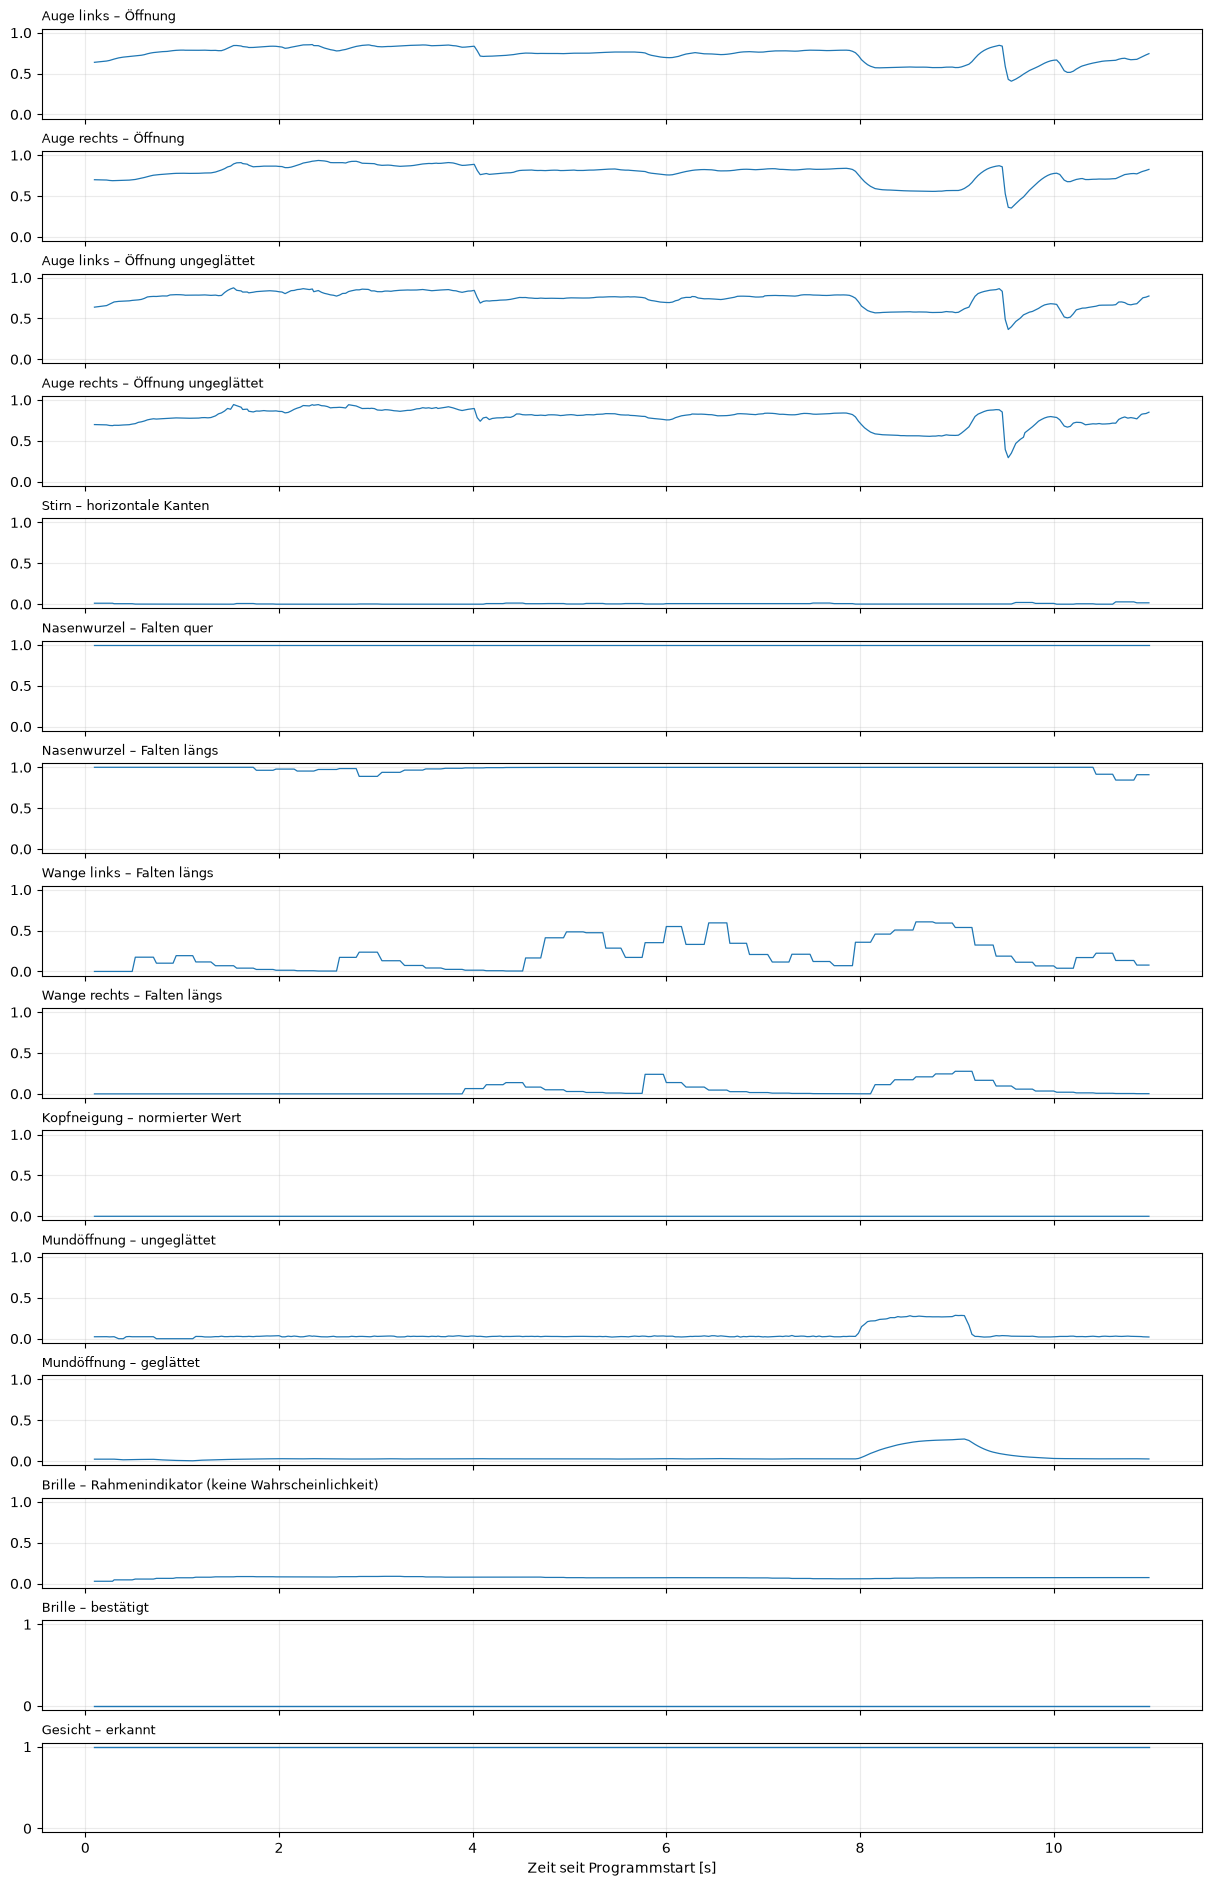

In [4]:
from log_show import auswerten

ergebnis = auswerten(PROJEKTORDNER / "logs")

# Optional eine bestimmte Datei statt des letzten Logs verwenden:
# ergebnis = auswerten(logdatei=PROJEKTORDNER / "logs" / "klassifikatoren_....csv")

# Daten und Grafik sind zur weiteren Bearbeitung verfügbar:
# ergebnis.daten, ergebnis.statistik, ergebnis.uebersicht, ergebnis.abbildung
